# Домашнее задание Основы машинного обучения
## EDA, подготовка данных, модели, метрики, CV, GridSearch, отбор признаков, гипотезы

**Датасет:** Mushroom Classification
- Классификация грибов: ядовитый или нет
- Реальные данные какого-то американского научно-микологического общества

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Загрузка данных

In [4]:
df = pd.read_csv("data/mushrooms.csv")

In [5]:
df.shape

(8124, 23)

In [6]:
df.columns

Index(['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='str')

In [7]:
print('Все колонки', df.columns.tolist())
df.info()

Все колонки ['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null 

## 2. EDA (Exploratory Data Analysis)

In [8]:
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [9]:
df.describe().round(2)

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


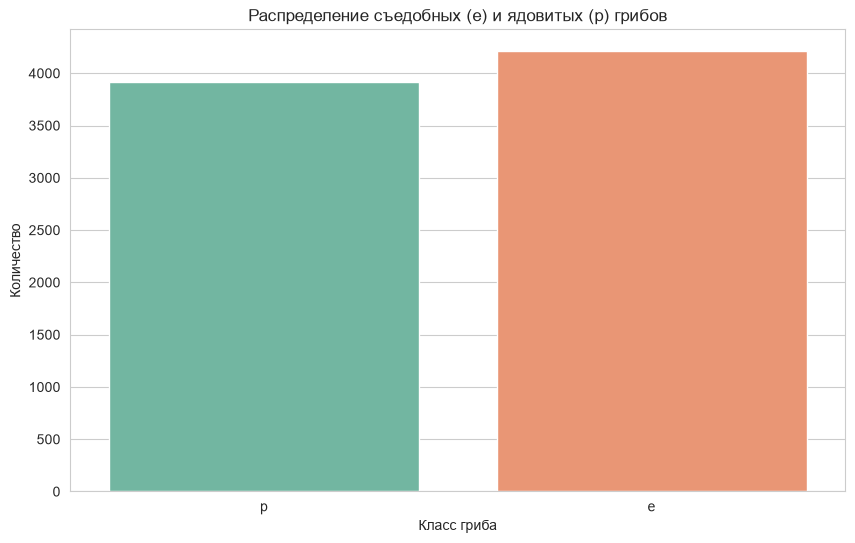

class
e    4208
p    3916
Name: count, dtype: int64


In [23]:
sns.countplot(data=df, x='class', palette='Set2')
plt.title('Распределение съедобных (e) и ядовитых (p) грибов')
plt.xlabel('Класс гриба')
plt.ylabel('Количество')
plt.show()

print(df['class'].value_counts())

**Прогуглил что в основном ядовитость определяется по трем признакам: вольва у основания ножки, юбка тоже на ножке и пластинчатый слой. Но в нашем датасете есть корреляция получше и это запах, ниже приведена таблица запахов и класса гриба(сьедобен/нет).**

In [22]:
# Словарь для удобства понимания, ибо весь датасет это просто 1 буковка сокращение от слова
odor_en_map = {
    'a': 'almond, миндаль',
    'l': 'anise, сладковатый/анис',
    'c': 'creosote, креозот/ деготь',
    'y': 'fishy, рыбный',
    'f': 'foul, вонючий',
    'm': 'musty, затхлый/заплесневелый',
    'n': 'none, нет запаха',
    'p': 'pungent, едкий/резкий',
    's': 'spicy, острый'
}

df['odor_word'] = df['odor'].map(odor_en_map)

df.groupby('odor_word')['class'].value_counts()


odor_word                     class
almond, миндаль               e         400
anise, сладковатый/анис       e         400
creosote, креозот/ деготь     p         192
fishy, рыбный                 p         576
foul, вонючий                 p        2160
musty, затхлый/заплесневелый  p          36
none, нет запаха              e        3408
                              p         120
pungent, едкий/резкий         p         256
spicy, острый                 p         576
Name: count, dtype: int64

**Из таблицы можно сделать вывод, что грибы с запахом миндаля,аниса,без запаха зачастую относятся к съедобным, построим график и проверим это. 

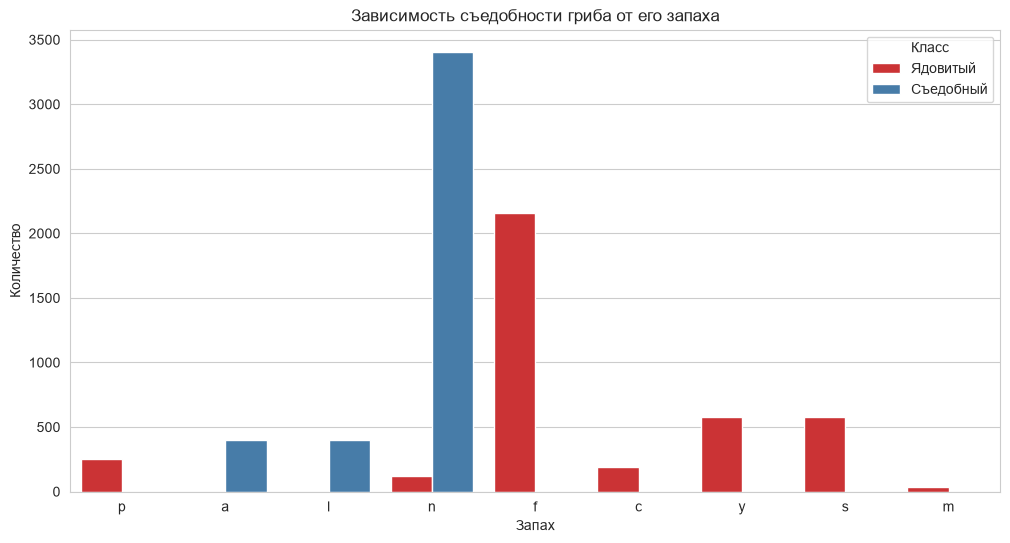

In [16]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='odor', hue='class', palette='Set1')
plt.title('Зависимость съедобности гриба от его запаха')
plt.xlabel('Запах')
plt.ylabel('Количество')
plt.legend(title='Класс', labels=['Ядовитый', 'Съедобный'])
plt.show()
